# Class 5: Deep Learning for Satellite Imagery with Convolutional Neural Networks (CNNs) - 2026

**Course:** Geocomputation & Spatial Ecology  
**Dataset:** [EuroSAT](https://github.com/phelber/EuroSAT) (Copernicus Sentinel-2 Satellite Multispectral / Optical Imagery)  

---

### Objectives
1. **Understand Spatial Imagery in Deep Learning:** Transition from 1D tabular pixels to 2D multi-channel spatial tensors $(C, H, W)$.
2. **Baseline Model (Multi-Layer Perceptron):** Understand why flat dense layers struggle with spatial context.
3. **Convolutional Neural Networks (CNNs):** Learn how spatial convolution kernels and pooling capture spatial patterns (textures, boundaries, shapes) in satellite imagery.
4. **Preventing Overfitting with Early Stopping:** Learn how to detect when a model stops generalizing to unseen satellite scenes and automatically halt training.
5. **Hyperparameter Tuning with Hyperopt:** Automate the search for optimal learning rates, batch sizes, and optimizers.
6. **Interpretability with Saliency Maps:** Inspect which satellite image features (e.g. roads, water borders, buildings) the CNN focuses on when predicting land cover classes.


    cd ~/SE_data
    git pull
    rsync -hvrPt --ignore-existing ~/SE_data/* /media/sf_LVM_shared/my_SE_data
    cd  /media/sf_LVM_shared/my_SE_data/exercise
    jupyter-lab CNN_satelite_Class5_2026.ipynb

In [1]:
# 1. Setup & Imports
import os
import glob
import time
import zipfile
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import Dataset, DataLoader, random_split

# Hyperparameter optimization
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Select compute device (GPU if available, else CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU Model: NVIDIA GeForce RTX 4090


## 2. Dataset Acquisition: EuroSAT (Sentinel-2)

The **EuroSAT** dataset is a benchmark dataset for Land Use and Land Cover (LULC) classification based on European Space Agency (ESA) **Sentinel-2** satellite observations.

It contains **27,000 georeferenced image patches** $(64 \times 64\text{ pixels})$ across **10 Land Cover classes**:
- **Annual Crop**
- **Forest**
- **Herbaceous Vegetation**
- **Highway**
- **Industrial**
- **Pasture**
- **Permanent Crop**
- **Residential**
- **River**
- **Sea Lake**

The cell below checks for the dataset locally. If not found, it downloads the clean RGB version (~94 MB) automatically.


In [2]:
# 2. Check and Download EuroSAT Dataset (~94 MB)
data_dir = "./geodata/EuroSAT"
extract_dir = os.path.join(data_dir, "2750")

# Possible locations where the dataset might be stored
search_paths = [
    extract_dir,
    "./EuroSAT/2750",
    "../geodata/EuroSAT/2750",
    "../../geodata/EuroSAT/2750"
]

dataset_path = None
for p in search_paths:
    if os.path.exists(p) and len(os.listdir(p)) > 0:
        dataset_path = p
        break

if dataset_path is None:
    os.makedirs(data_dir, exist_ok=True)
    zip_path = os.path.join(data_dir, "EuroSAT.zip")
    url = "https://huggingface.co/datasets/torchgeo/eurosat/resolve/main/EuroSAT.zip"
    print("EuroSAT dataset not found locally. Downloading from Hugging Face CDN (~94 MB)...")
    urllib.request.urlretrieve(url, zip_path)
    print("Extracting archive...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    dataset_path = extract_dir
    print("Download and extraction complete!")
else:
    print(f"Found existing EuroSAT dataset at: {dataset_path}")

# List classes
classes = sorted([d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))])
print(f"\nDiscovered {len(classes)} classes:")
for i, c in enumerate(classes):
    count = len(glob.glob(os.path.join(dataset_path, c, "*.jpg")))
    print(f"  [{i}] {c:<22s} ({count} images)")


Found existing EuroSAT dataset at: ./geodata/EuroSAT/2750

Discovered 10 classes:
  [0] AnnualCrop             (3000 images)
  [1] Forest                 (3000 images)
  [2] HerbaceousVegetation   (3000 images)
  [3] Highway                (2500 images)
  [4] Industrial             (2500 images)
  [5] Pasture                (2000 images)
  [6] PermanentCrop          (2500 images)
  [7] Residential            (3000 images)
  [8] River                  (2500 images)
  [9] SeaLake                (3000 images)


### PyTorch Dataset & DataLoaders

In PyTorch, data loading is handled cleanly by sub-classing `torch.utils.data.Dataset`.
For each image:
1. We read the JPEG satellite patch with `PIL.Image.open()`.
2. Convert pixel values from $[0, 255]$ integers to $[0.0, 1.0]$ floats.
3. Transpose dimensions from image shape `(Height, Width, Channels)` to PyTorch format `(Channels, Height, Width)` $\rightarrow (3, 64, 64)$.


In [3]:
# 3. Define EuroSAT Dataset & Create Train / Val / Test Splits

class EuroSATDataset(Dataset):
    """PyTorch Dataset for EuroSAT satellite image patches."""
    def __init__(self, file_paths, labels):
        self.file_paths = file_paths
        self.labels = labels
        
    def __len__(self):
        return len(self.file_paths)
        
    def __getitem__(self, idx):
        # Open satellite patch and ensure 3 RGB channels
        img = Image.open(self.file_paths[idx]).convert('RGB')
        arr = np.array(img, dtype=np.float32) / 255.0  # Normalize to [0, 1]
        
        # Transpose (H, W, C) -> (C, H, W) for PyTorch
        tensor = torch.from_numpy(arr).permute(2, 0, 1)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return tensor, label

# Collect all image paths and labels
all_files = []
all_labels = []
for idx, cls_name in enumerate(classes):
    cls_files = sorted(glob.glob(os.path.join(dataset_path, cls_name, "*.jpg")))
    all_files.extend(cls_files)
    all_labels.extend([idx] * len(cls_files))

# Shuffle reproducibly
indices = np.random.permutation(len(all_files))
all_files = [all_files[i] for i in indices]
all_labels = [all_labels[i] for i in indices]

# For classroom exercises, we use a balanced subset (e.g. 3,000 images)
# to keep training fast (a few seconds per epoch). Set to None to use all 27,000.
SUBSET_SIZE = 3000
if SUBSET_SIZE is not None and SUBSET_SIZE < len(all_files):
    selected_files = all_files[:SUBSET_SIZE]
    selected_labels = all_labels[:SUBSET_SIZE]
else:
    selected_files = all_files
    selected_labels = all_labels

# 70% Train, 15% Validation, 15% Test
n_total = len(selected_files)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val

train_dataset = EuroSATDataset(selected_files[:n_train], selected_labels[:n_train])
val_dataset   = EuroSATDataset(selected_files[n_train:n_train+n_val], selected_labels[n_train:n_train+n_val])
test_dataset  = EuroSATDataset(selected_files[n_train+n_val:], selected_labels[n_train+n_val:])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Data ready:")
print(f"  Training samples:   {len(train_dataset)}")
print(f"  Validation samples: {len(val_dataset)}")
print(f"  Test samples:       {len(test_dataset)}")


Data ready:
  Training samples:   2100
  Validation samples: 450
  Test samples:       450


### Visualizing Sentinel-2 Land Cover Patches

Let's display one sample patch from each of the 10 classes to inspect the satellite imagery.


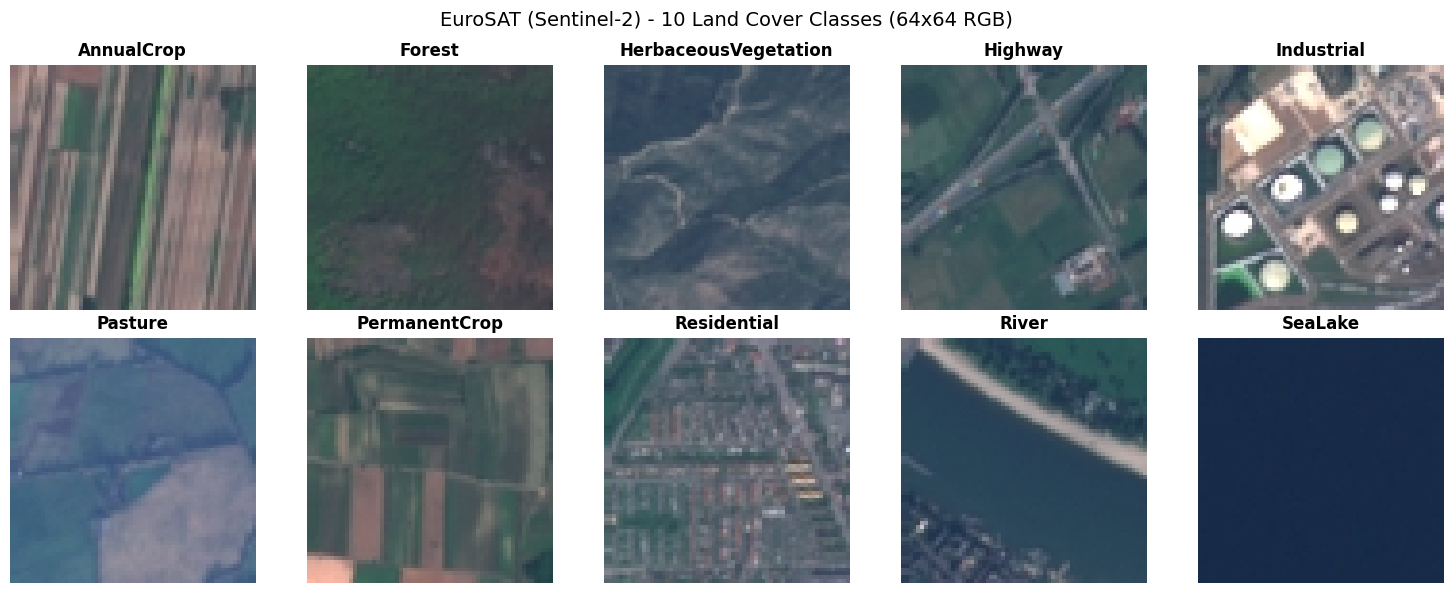

In [4]:
# 4. Display a sample satellite patch from each class
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for idx, cls_name in enumerate(classes):
    cls_files = glob.glob(os.path.join(dataset_path, cls_name, "*.jpg"))
    sample_img = Image.open(cls_files[0])
    
    axes[idx].imshow(sample_img)
    axes[idx].set_title(cls_name, fontsize=12, fontweight='bold')
    axes[idx].axis('off')

plt.suptitle("EuroSAT (Sentinel-2) - 10 Land Cover Classes (64x64 RGB)", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()


## 3. Training & Evaluation Utility Functions

We define reusable functions to train a model for several epochs and track loss and accuracy.


In [5]:
# 5. Helper function for training and evaluation
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10, verbose=True):
    """Trains a PyTorch model and tracks loss and accuracy per epoch."""
    history = {
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': []
    }
    
    for epoch in range(1, num_epochs + 1):
        # --- Training Phase ---
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            
        train_loss = running_loss / total
        train_acc = correct / total
        
        # --- Validation Phase ---
        model.eval()
        val_loss_running = 0.0
        val_correct = 0
        val_total = 0
        
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                val_loss_running += loss.item() * images.size(0)
                preds = outputs.argmax(dim=1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)
                
        val_loss = val_loss_running / val_total
        val_acc = val_correct / val_total
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        
        if verbose:
            print(f"Epoch [{epoch:02d}/{num_epochs:02d}] "
                  f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.1f}% | "
                  f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.1f}%")
            
    return history

def plot_training_history(history, title_prefix="Model"):
    """Plots training and validation loss & accuracy curves side-by-side."""
    epochs = range(1, len(history['train_loss']) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Loss plot
    ax1.plot(epochs, history['train_loss'], 'o-', label='Train Loss', color='#1f77b4', linewidth=2)
    ax1.plot(epochs, history['val_loss'], 's--', label='Val Loss', color='#ff7f0e', linewidth=2)
    ax1.set_title(f"{title_prefix} - Loss Curve", fontsize=13, fontweight='bold')
    ax1.set_xlabel("Epoch", fontsize=11)
    ax1.set_ylabel("Cross Entropy Loss", fontsize=11)
    ax1.grid(True, linestyle=":", alpha=0.6)
    ax1.legend(fontsize=11)
    
    # Accuracy plot
    ax2.plot(epochs, [a * 100 for a in history['train_acc']], 'o-', label='Train Acc', color='#2ca02c', linewidth=2)
    ax2.plot(epochs, [a * 100 for a in history['val_acc']], 's--', label='Val Acc', color='#d62728', linewidth=2)
    ax2.set_title(f"{title_prefix} - Accuracy Curve", fontsize=13, fontweight='bold')
    ax2.set_xlabel("Epoch", fontsize=11)
    ax2.set_ylabel("Accuracy (%)", fontsize=11)
    ax2.grid(True, linestyle=":", alpha=0.6)
    ax2.legend(fontsize=11)
    
    plt.tight_layout()
    plt.show()


## 4. Model 1: Baseline Multi-Layer Perceptron (FFnet)

A standard Feed-Forward network (Multi-Layer Perceptron) requires flattening the 2D image into a 1D vector:
$$\text{Input Dimension} = 3 \text{ channels} \times 64 \text{ pixels} \times 64 \text{ pixels} = 12,288 \text{ features}$$

### The Limitation for Geocomputation:
Flattening destroys the spatial topology of the satellite image:
- Pixel $(x, y)$ loses its direct spatial neighborhood with $(x+1, y)$ and $(x, y+1)$.
- Rotations, spatial shifts, and texture patterns cannot be learned efficiently without massive parameter counts.


--- Training Baseline Multi-Layer Perceptron (FFnet) ---


Epoch [01/10] Train Loss: 2.2809 | Train Acc: 15.4% | Val Loss: 2.1540 | Val Acc: 11.8%


Epoch [02/10] Train Loss: 1.9672 | Train Acc: 22.9% | Val Loss: 1.9127 | Val Acc: 19.6%


Epoch [03/10] Train Loss: 1.8648 | Train Acc: 25.4% | Val Loss: 1.8612 | Val Acc: 27.8%


Epoch [04/10] Train Loss: 1.8198 | Train Acc: 27.0% | Val Loss: 1.8466 | Val Acc: 32.0%


Epoch [05/10] Train Loss: 1.7920 | Train Acc: 29.3% | Val Loss: 1.8765 | Val Acc: 28.2%


Epoch [06/10] Train Loss: 1.7852 | Train Acc: 29.5% | Val Loss: 1.7453 | Val Acc: 32.4%


Epoch [07/10] Train Loss: 1.7323 | Train Acc: 32.8% | Val Loss: 1.7577 | Val Acc: 32.7%


Epoch [08/10] Train Loss: 1.7063 | Train Acc: 32.8% | Val Loss: 1.7011 | Val Acc: 36.7%


Epoch [09/10] Train Loss: 1.6649 | Train Acc: 34.4% | Val Loss: 1.6809 | Val Acc: 34.7%


Epoch [10/10] Train Loss: 1.6820 | Train Acc: 35.6% | Val Loss: 1.6802 | Val Acc: 37.1%


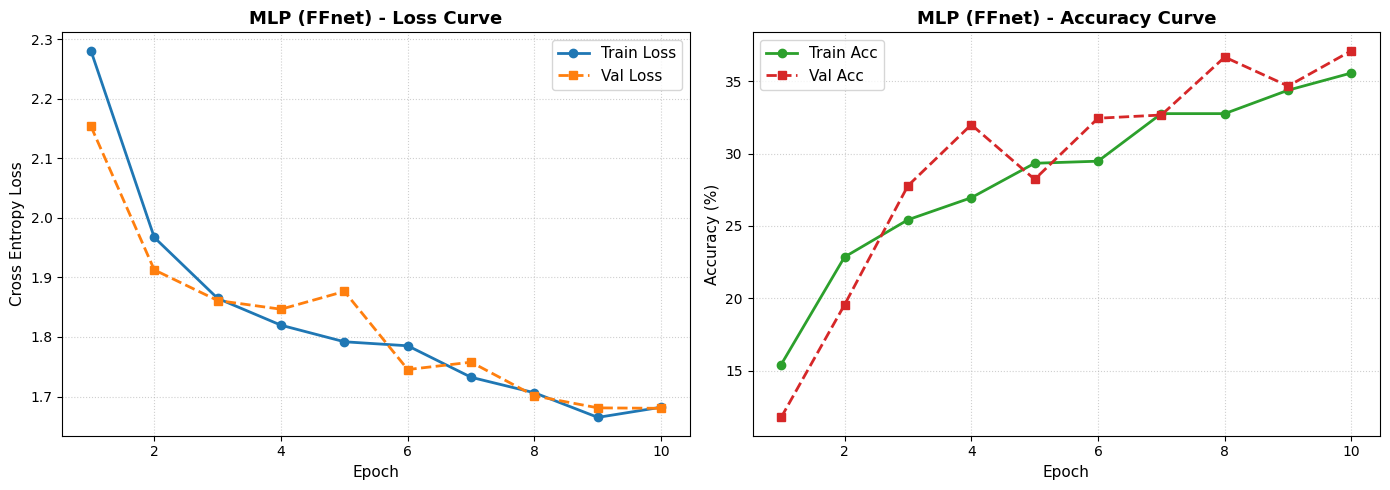

In [6]:
# 6. Define and Train the Feed-Forward Multi-Layer Perceptron (FFnet)
class FFnet(nn.Module):
    def __init__(self, in_features=3 * 64 * 64, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )
        
    def forward(self, x):
        return self.net(x)

mlp_model = FFnet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp_model.parameters(), lr=0.001)

print("--- Training Baseline Multi-Layer Perceptron (FFnet) ---")
mlp_history = train_model(mlp_model, train_loader, val_loader, criterion, optimizer, num_epochs=10)
plot_training_history(mlp_history, title_prefix="MLP (FFnet)")


## 5. Model 2: Convolutional Neural Network (CNNet)

Convolutional Neural Networks preserve spatial dimensions using two core building blocks:

1. **Convolutional Filters (Kernels):** Small moving filters (e.g. $3 \times 3$) that slide across the image, computing dot products to detect local spatial patterns (edges, borders, vegetation textures, building geometry). This is identical in concept to focal convolution filters in GIS (like Sobel edge filters).
2. **Pooling Layers (Downsampling):** Max-pooling selects the strongest feature in a local $2 \times 2$ window, reducing image resolution while maintaining shift invariance.

### Architecture:
- **Block 1:** Conv2D $(3 \rightarrow 32) \rightarrow$ BatchNorm $\rightarrow$ ReLU $\rightarrow$ MaxPool $(64 \times 64 \rightarrow 32 \times 32)$
- **Block 2:** Conv2D $(32 \rightarrow 64) \rightarrow$ BatchNorm $\rightarrow$ ReLU $\rightarrow$ MaxPool $(32 \times 32 \rightarrow 16 \times 16)$
- **Block 3:** Conv2D $(64 \rightarrow 128) \rightarrow$ BatchNorm $\rightarrow$ ReLU $\rightarrow$ MaxPool $(16 \times 16 \rightarrow 8 \times 8)$
- **Classifier:** Flatten $\rightarrow$ Linear $(8192 \rightarrow 128) \rightarrow$ ReLU $\rightarrow$ Dropout $(0.3) \rightarrow$ Linear $(128 \rightarrow 10)$


--- Training Convolutional Neural Network (CNNet) ---


Epoch [01/10] Train Loss: 1.6396 | Train Acc: 43.2% | Val Loss: 1.1849 | Val Acc: 56.4%


Epoch [02/10] Train Loss: 1.2079 | Train Acc: 57.0% | Val Loss: 0.9639 | Val Acc: 69.1%


Epoch [03/10] Train Loss: 1.0918 | Train Acc: 61.0% | Val Loss: 0.9767 | Val Acc: 64.0%


Epoch [04/10] Train Loss: 0.9784 | Train Acc: 64.5% | Val Loss: 1.0578 | Val Acc: 61.1%


Epoch [05/10] Train Loss: 0.9198 | Train Acc: 67.1% | Val Loss: 1.0398 | Val Acc: 67.3%


Epoch [06/10] Train Loss: 0.8296 | Train Acc: 70.2% | Val Loss: 1.0029 | Val Acc: 69.3%


Epoch [07/10] Train Loss: 0.7977 | Train Acc: 70.7% | Val Loss: 0.9739 | Val Acc: 69.1%


Epoch [08/10] Train Loss: 0.7713 | Train Acc: 73.6% | Val Loss: 1.2347 | Val Acc: 57.1%


Epoch [09/10] Train Loss: 0.6982 | Train Acc: 74.5% | Val Loss: 0.9708 | Val Acc: 70.2%


Epoch [10/10] Train Loss: 0.6877 | Train Acc: 74.6% | Val Loss: 0.6998 | Val Acc: 74.2%


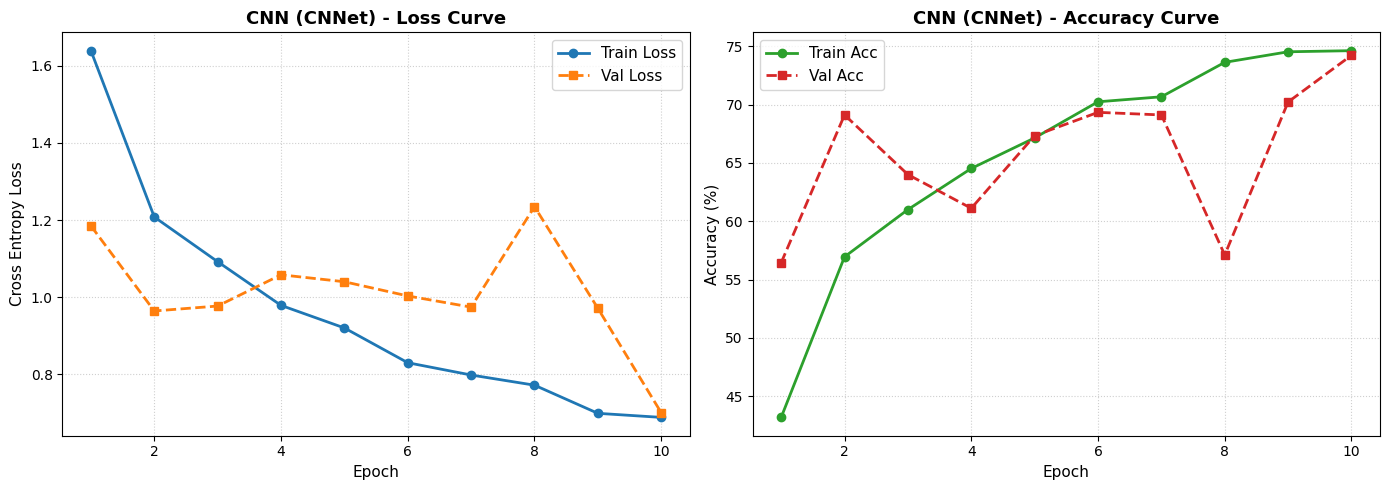

In [7]:
# 7. Define and Train the Convolutional Neural Network (CNNet)
class CNNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 64x64 -> 32x32
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            # Block 2: 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            # Block 3: 16x16 -> 8x8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
        
    def forward(self, x):
        return self.classifier(self.features(x))

cnn_model = CNNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

print("--- Training Convolutional Neural Network (CNNet) ---")
cnn_history = train_model(cnn_model, train_loader, val_loader, criterion, optimizer, num_epochs=10)
plot_training_history(cnn_history, title_prefix="CNN (CNNet)")


### Model Comparison: MLP vs. CNN

Let's compare the validation accuracy of the MLP baseline against the CNN.


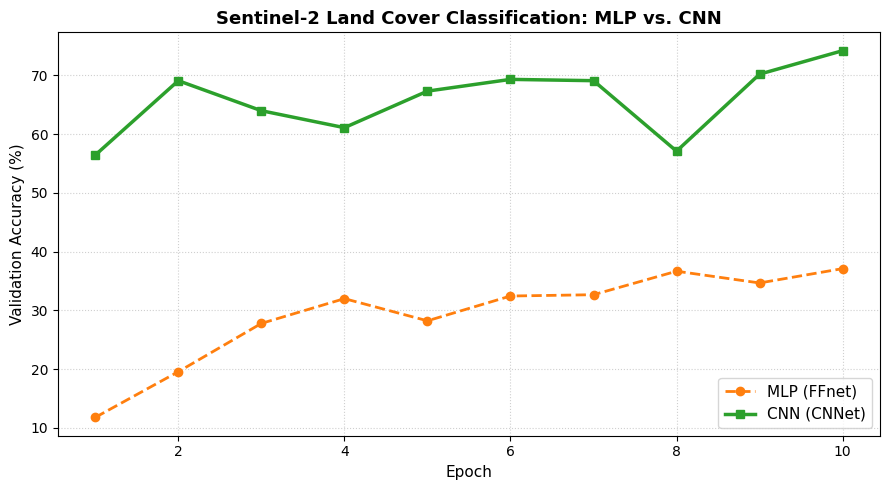

Final MLP Validation Accuracy: 37.11%
Final CNN Validation Accuracy: 74.22%


In [8]:
# 8. Compare Validation Accuracy of MLP vs CNN
epochs = range(1, len(mlp_history['val_acc']) + 1)
plt.figure(figsize=(9, 5))
plt.plot(epochs, [a * 100 for a in mlp_history['val_acc']], 'o--', label='MLP (FFnet)', color='#ff7f0e', linewidth=2)
plt.plot(epochs, [a * 100 for a in cnn_history['val_acc']], 's-', label='CNN (CNNet)', color='#2ca02c', linewidth=2.5)

plt.title("Sentinel-2 Land Cover Classification: MLP vs. CNN", fontsize=13, fontweight='bold')
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Validation Accuracy (%)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(f"Final MLP Validation Accuracy: {mlp_history['val_acc'][-1]*100:.2f}%")
print(f"Final CNN Validation Accuracy: {cnn_history['val_acc'][-1]*100:.2f}%")


## 6. Overfitting & Early Stopping

### What is Overfitting?
When training a deep network:
- **Phase 1 (Learning):** Both Training Loss and Validation Loss decrease. The model is learning real spatial structures.
- **Phase 2 (Overfitting):** Training Loss continues to fall towards zero, but **Validation Loss starts climbing**. The model has memorized specific training patches and is losing the ability to generalize to new satellite imagery.

### How Early Stopping Works:
1. Track the **Validation Loss** after every epoch.
2. If Validation Loss reaches a new minimum, save a copy of the model weights.
3. If Validation Loss fails to improve for `patience` consecutive epochs, halt training automatically and restore the best weights.


In [9]:
# 9. Early Stopping Implementation & Side-by-Side Comparison Experiment
import copy

class EarlyStopping:
    """Monitors validation loss and stops training when no improvement is observed."""
    def __init__(self, patience=3, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_model_weights = None
        self.best_epoch = 0

    def __call__(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_epoch = epoch
            self.best_model_weights = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

def train_with_early_stopping(model, train_loader, val_loader, criterion, optimizer, 
                              num_epochs=20, use_early_stopping=True, patience=3):
    """Trains a model with optional early stopping."""
    history = {'train_loss': [], 'val_loss': []}
    early_stopper = EarlyStopping(patience=patience) if use_early_stopping else None
    stopped_epoch = num_epochs
    
    for epoch in range(1, num_epochs + 1):
        model.train()
        running_loss = 0.0
        total = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)
            total += labels.size(0)
            
        train_loss = running_loss / total
        
        model.eval()
        v_loss_running = 0.0
        v_total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                v_loss = criterion(model(images), labels)
                v_loss_running += v_loss.item() * images.size(0)
                v_total += labels.size(0)
                
        val_loss = v_loss_running / v_total
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        
        if use_early_stopping:
            early_stopper(val_loss, model, epoch)
            if early_stopper.early_stop:
                stopped_epoch = epoch
                print(f"  [EarlyStopping] Halted at epoch {epoch}. Restoring best weights from epoch {early_stopper.best_epoch} (val loss: {early_stopper.best_loss:.4f})")
                model.load_state_dict(early_stopper.best_model_weights)
                break
                
    return history, stopped_epoch, (early_stopper.best_epoch if early_stopper else None)

# Run Comparison Experiment:
# We create a noisy, smaller training set (400 samples) so overfitting happens noticeably within 20 epochs
small_train_loader = DataLoader(EuroSATDataset(selected_files[:400], selected_labels[:400]), batch_size=32, shuffle=True)

print("1. Running Complete Training (Unconstrained - 20 Epochs)...")
torch.manual_seed(42)
full_model = CNNet().to(device)
full_opt = optim.Adam(full_model.parameters(), lr=0.001)
full_hist, _, _ = train_with_early_stopping(
    full_model, small_train_loader, val_loader, criterion, full_opt,
    num_epochs=20, use_early_stopping=False
)

print("\n2. Running Early Stopped Training (patience = 3)...")
torch.manual_seed(42)
es_model = CNNet().to(device)
es_opt = optim.Adam(es_model.parameters(), lr=0.001)
es_hist, es_stop_epoch, es_best_epoch = train_with_early_stopping(
    es_model, small_train_loader, val_loader, criterion, es_opt,
    num_epochs=20, use_early_stopping=True, patience=3
)


1. Running Complete Training (Unconstrained - 20 Epochs)...



2. Running Early Stopped Training (patience = 3)...


  [EarlyStopping] Halted at epoch 15. Restoring best weights from epoch 12 (val loss: 1.0108)


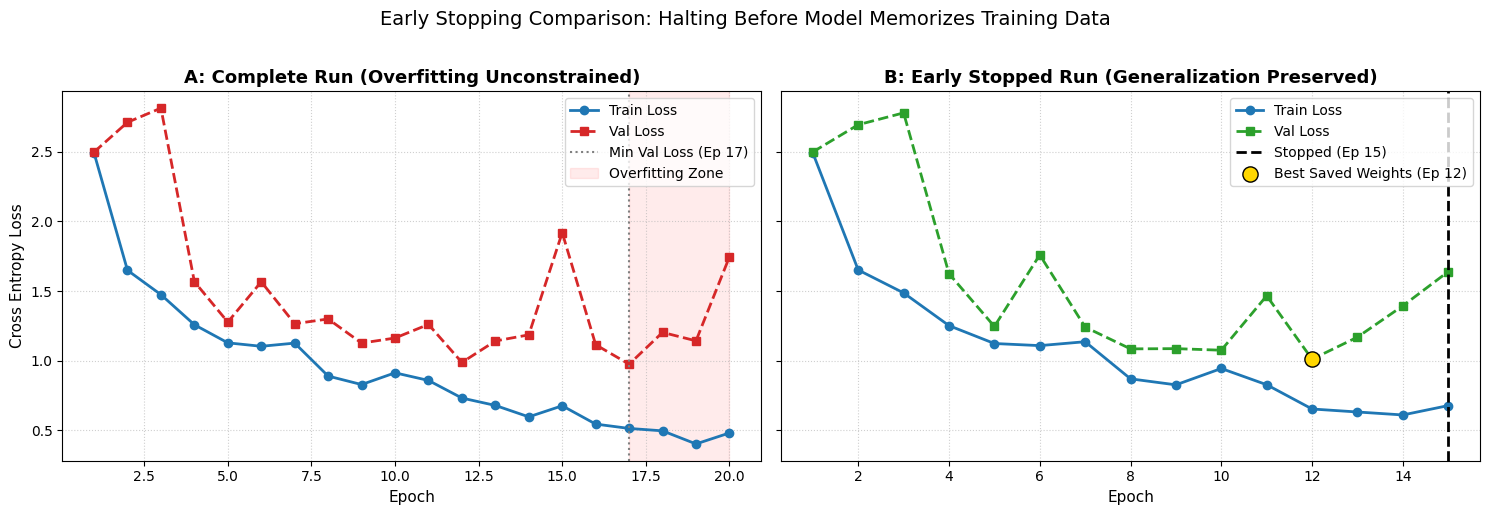

In [10]:
# 10. Side-by-Side Plot: Unconstrained Overfitting vs. Early Stopping
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Plot A: Complete Unconstrained Training
epochs_full = range(1, len(full_hist['train_loss']) + 1)
ax1.plot(epochs_full, full_hist['train_loss'], 'o-', color='#1f77b4', label='Train Loss', linewidth=2)
ax1.plot(epochs_full, full_hist['val_loss'], 's--', color='#d62728', label='Val Loss', linewidth=2)

# Highlight overfitting zone
min_val_idx = int(np.argmin(full_hist['val_loss'])) + 1
ax1.axvline(min_val_idx, color='gray', linestyle=':', label=f'Min Val Loss (Ep {min_val_idx})')
ax1.axvspan(min_val_idx, len(full_hist['train_loss']), color='red', alpha=0.08, label='Overfitting Zone')

ax1.set_title("A: Complete Run (Overfitting Unconstrained)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Cross Entropy Loss", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc='upper right', fontsize=10)

# Plot B: Early Stopped Run
epochs_es = range(1, len(es_hist['train_loss']) + 1)
ax2.plot(epochs_es, es_hist['train_loss'], 'o-', color='#1f77b4', label='Train Loss', linewidth=2)
ax2.plot(epochs_es, es_hist['val_loss'], 's--', color='#2ca02c', label='Val Loss', linewidth=2)
ax2.axvline(es_stop_epoch, color='black', linestyle='--', linewidth=2, label=f'Stopped (Ep {es_stop_epoch})')
ax2.scatter(es_best_epoch, es_hist['val_loss'][es_best_epoch - 1], color='gold', s=120, zorder=5, 
            edgecolor='black', label=f'Best Saved Weights (Ep {es_best_epoch})')

ax2.set_title("B: Early Stopped Run (Generalization Preserved)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Epoch", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc='upper right', fontsize=10)

plt.suptitle("Early Stopping Comparison: Halting Before Model Memorizes Training Data", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## 7. Hyperparameter Tuning with Hyperopt

A machine learning model contains parameters learned during backpropagation (weights, biases) and **hyperparameters** set before training (learning rate, optimizer type, batch size).

Rather than guessing hyperparameters manually, **Hyperopt** uses Bayesian Optimization with a Tree of Parzen Estimators (TPE) to intelligently sample candidate values based on previous performance.

In this demonstration, we search over:
- `lr`: Continuous log-uniform distribution between $10^{-4}$ and $10^{-2}$.
- `optimizer`: Choice between `Adam` and `SGD`.
- `batch_size`: Choice between `32` and `64`.


In [11]:
# 11. Define Search Space & Objective Function with Hyperopt
space = {
    'lr': hp.loguniform('lr', np.log(1e-4), np.log(1e-2)),
    'optimizer': hp.choice('optimizer', ['Adam', 'SGD']),
    'batch_size': hp.choice('batch_size', [32, 64])
}

trial_records = []

def objective(params):
    """Objective function evaluated by Hyperopt on validation loss."""
    lr = params['lr']
    opt_name = params['optimizer']
    batch_size = params['batch_size']
    
    # Create dataloaders for the chosen batch size
    t_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    v_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    
    # Initialize a fresh CNN
    model = CNNet().to(device)
    crit = nn.CrossEntropyLoss()
    if opt_name == 'Adam':
        opt = optim.Adam(model.parameters(), lr=lr)
    else:
        opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
        
    # Quick 3-epoch evaluation
    for epoch in range(3):
        model.train()
        for x, y in t_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            crit(model(x), y).backward()
            opt.step()
            
    # Measure validation loss
    model.eval()
    val_loss = 0.0
    val_total = 0
    with torch.no_grad():
        for x, y in v_loader:
            x, y = x.to(device), y.to(device)
            val_loss += crit(model(x), y).item() * len(y)
            val_total += len(y)
            
    final_val_loss = val_loss / val_total
    
    trial_records.append({
        'trial': len(trial_records) + 1,
        'lr': lr,
        'optimizer': opt_name,
        'batch_size': batch_size,
        'val_loss': final_val_loss
    })
    
    return {'loss': final_val_loss, 'status': STATUS_OK}

print("Running 5 Hyperopt Trials...")
trials = Trials()
best_params = fmin(
    fn=objective,
    space=space,
    algo=tpe.suggest,
    max_evals=5,
    trials=trials,
    rstate=np.random.default_rng(42)
)

print("\n--- Hyperopt Search Summary ---")
print(f"{'Trial':<7} | {'Optimizer':<10} | {'Batch Size':<10} | {'Learning Rate':<14} | {'Val Loss':<10}")
print("-" * 65)
for t in trial_records:
    print(f"{t['trial']:<7} | {t['optimizer']:<10} | {t['batch_size']:<10} | {t['lr']:<14.6f} | {t['val_loss']:<10.4f}")


Running 5 Hyperopt Trials...
  0%|                                     | 0/5 [00:00<?, ?trial/s, best loss=?]

 20%|██▏        | 1/5 [00:01<00:06,  1.68s/trial, best loss: 1.9518038378821478]

 40%|████▍      | 2/5 [00:03<00:05,  1.85s/trial, best loss: 0.9551945903566148]

 60%|██████▌    | 3/5 [00:05<00:03,  1.95s/trial, best loss: 0.9279482263988919]

 80%|████████▊  | 4/5 [00:07<00:01,  1.92s/trial, best loss: 0.9279482263988919]

100%|███████████| 5/5 [00:09<00:00,  1.81s/trial, best loss: 0.9279482263988919]

100%|███████████| 5/5 [00:09<00:00,  1.84s/trial, best loss: 0.9279482263988919]



--- Hyperopt Search Summary ---
Trial   | Optimizer  | Batch Size | Learning Rate  | Val Loss  
-----------------------------------------------------------------
1       | Adam       | 64         | 0.001739       | 1.9518    
2       | SGD        | 32         | 0.001646       | 0.9552    
3       | Adam       | 32         | 0.000140       | 0.9279    
4       | SGD        | 32         | 0.000266       | 1.3217    
5       | Adam       | 64         | 0.000156       | 0.9516    


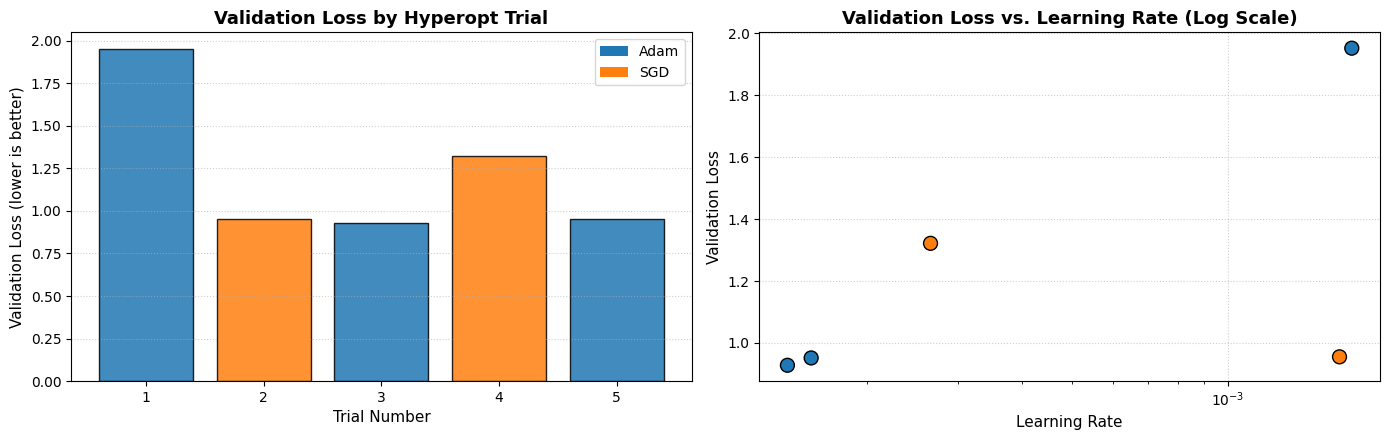

In [12]:
# 12. Plot Hyperopt Trial Results
trials_list = [t['trial'] for t in trial_records]
losses = [t['val_loss'] for t in trial_records]
optimizers = [t['optimizer'] for t in trial_records]
lrs = [t['lr'] for t in trial_records]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot 1: Trial vs Loss
colors = ['#1f77b4' if o == 'Adam' else '#ff7f0e' for o in optimizers]
bars = ax1.bar(trials_list, losses, color=colors, alpha=0.85, edgecolor='black')
ax1.set_title("Validation Loss by Hyperopt Trial", fontsize=13, fontweight='bold')
ax1.set_xlabel("Trial Number", fontsize=11)
ax1.set_ylabel("Validation Loss (lower is better)", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.6, axis='y')

# Add legend for optimizers
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#1f77b4', label='Adam'), Patch(facecolor='#ff7f0e', label='SGD')]
ax1.legend(handles=legend_elements, loc='upper right', fontsize=10)

# Plot 2: Learning Rate vs Loss
ax2.scatter(lrs, losses, c=colors, s=100, edgecolor='black', zorder=5)
ax2.set_xscale('log')
ax2.set_title("Validation Loss vs. Learning Rate (Log Scale)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Learning Rate", fontsize=11)
ax2.set_ylabel("Validation Loss", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 8. Model Interpretability: Saliency Maps

In remote sensing and Earth observation, understanding **why** a neural network classified a satellite scene is crucial for validation and trust.

A **Saliency Map** measures how sensitive the output class score $S_c$ is to small changes in each pixel $(i, j)$ of the input image $I$:
$$\text{Saliency}_{i,j} = \max_{c \in \{R, G, B\}} \left| \frac{\partial S_c}{\partial I_{c, i, j}} \right|$$

Pixels with high gradients have the highest impact on the model's decision (e.g. roads for the *Highway* class, water contours for the *River* class, or structural boundaries for *Industrial* buildings).


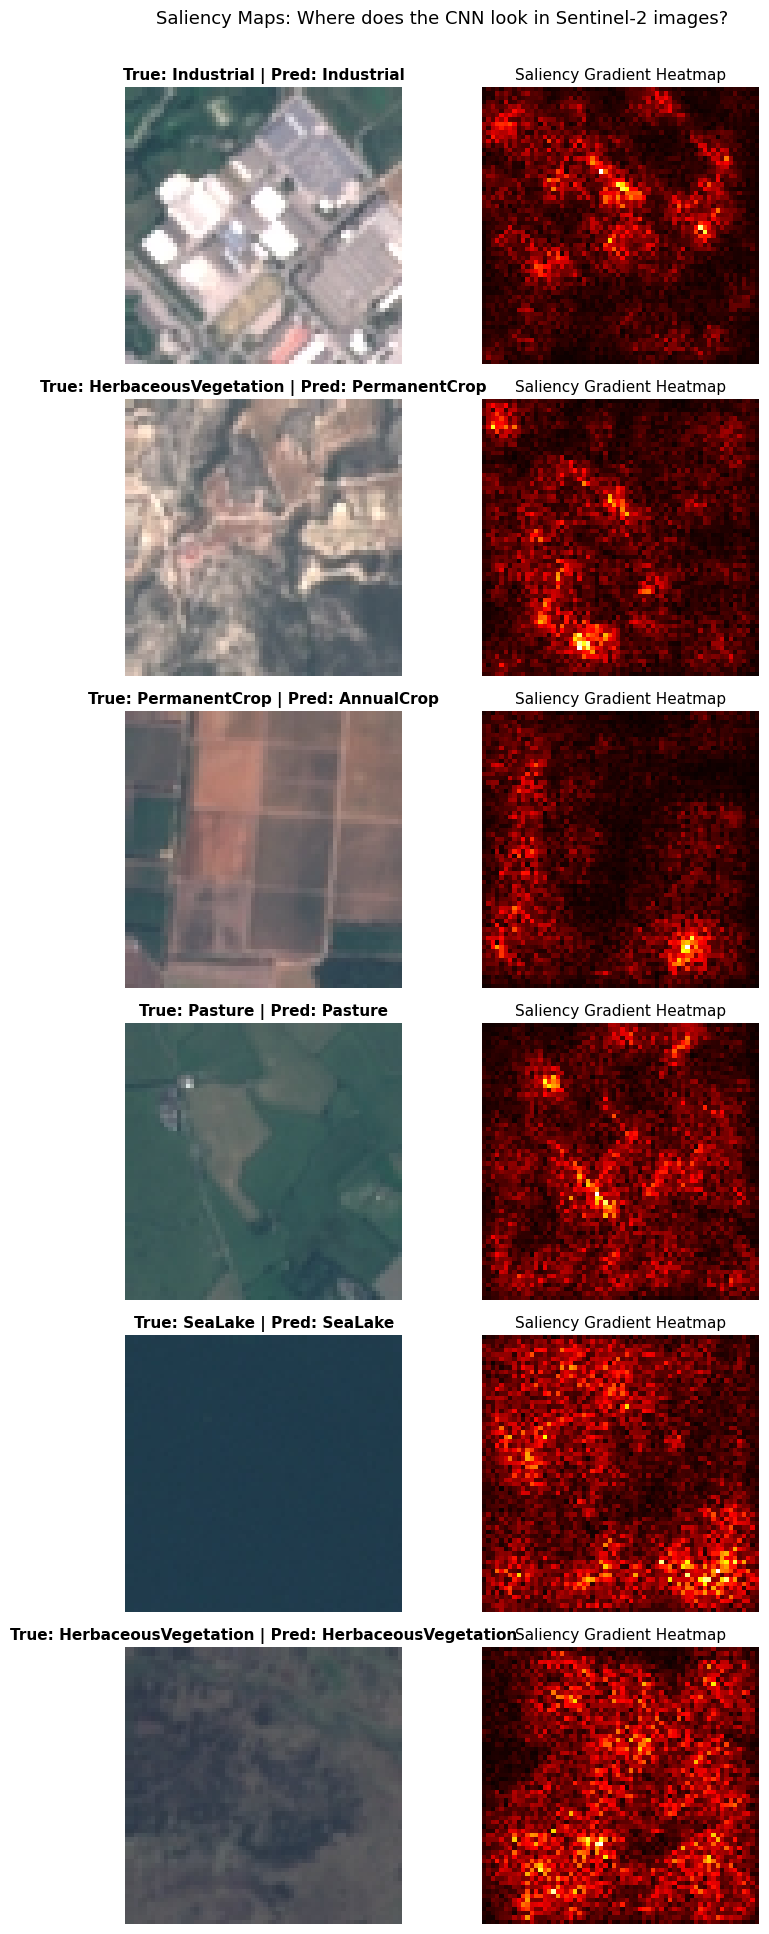

In [13]:
# 13. Compute and Visualize Saliency Maps on EuroSAT Test Images
cnn_model.eval()

# Select 6 diverse test images
sample_indices = [0, 10, 25, 40, 55, 70]
fig, axes = plt.subplots(len(sample_indices), 2, figsize=(8, 3.2 * len(sample_indices)))

for row, idx in enumerate(sample_indices):
    image_tensor, true_label = test_dataset[idx]
    image_tensor = image_tensor.unsqueeze(0).to(device)  # Add batch dim (1, 3, 64, 64)
    image_tensor.requires_grad_()
    
    # Forward pass
    output = cnn_model(image_tensor)
    pred_label = output.argmax(dim=1).item()
    
    # Backward pass for the predicted class score
    score = output[0, pred_label]
    score.backward()
    
    # Saliency is the maximum absolute gradient across the 3 RGB color channels
    saliency, _ = torch.max(image_tensor.grad.data.abs(), dim=1)
    saliency = saliency.squeeze(0).cpu().numpy()
    
    # Normalize saliency to [0, 1] for visualization
    saliency_norm = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)
    
    # Original image for plotting (H, W, C)
    orig_img = image_tensor.squeeze(0).detach().permute(1, 2, 0).cpu().numpy()
    orig_img = np.clip(orig_img, 0, 1)
    
    # Plot original image
    axes[row, 0].imshow(orig_img)
    axes[row, 0].set_title(f"True: {classes[true_label]} | Pred: {classes[pred_label]}", fontsize=11, fontweight='bold')
    axes[row, 0].axis('off')
    
    # Plot saliency map
    im = axes[row, 1].imshow(saliency_norm, cmap='hot')
    axes[row, 1].set_title(f"Saliency Gradient Heatmap", fontsize=11)
    axes[row, 1].axis('off')

plt.suptitle("Saliency Maps: Where does the CNN look in Sentinel-2 images?", fontsize=13, y=1.005)
plt.tight_layout()
plt.show()


## 9. Key Takeaways for Geocomputation & Earth Observation

1. **Spatial Representation Matters:**
   - Flattening satellite imagery into 1D vectors for a Multi-Layer Perceptron destroys 2D spatial relationships.
   - Convolutional Neural Networks (CNNs) preserve 2D topology and extract hierarchical spatial features (edges $\rightarrow$ textures $\rightarrow$ complex land-use patterns).
2. **Sentinel-2 & Remote Sensing Integration:**
   - Sentinel-2 imagery can be seamlessly loaded with standard PyTorch `Dataset` loaders without reliance on legacy `.mat` files.
3. **Preventing Overfitting:**
   - When training deep models on finite Earth Observation data, monitoring validation loss is essential.
   - **Early Stopping** halts training at the exact point where generalization stops improving and restores the optimal weights.
4. **Hyperparameter Tuning:**
   - Bayesian Optimization (`hyperopt`) automates selecting learning rates, optimizers, and batch sizes without guesswork.
5. **Interpretability:**
   - Gradient-based saliency maps confirm whether the CNN is focusing on meaningful spatial structures (roads, building roofs, river bends) or spurious background artifacts.
